# SDXL × DrawBench — Evaluation (Colab)

Compares Standard Sampling vs Z-Sampling on all 200 DrawBench prompts × 3 seeds.

**Metrics** (from the paper's Table 1, SDXL + DrawBench column):
- HPS v2 ↑
- AES (Aesthetic Score) ↑
- PickScore ↑
- IR (ImageReward) ↑

**Dataset**: 1200 images total (600 standard + 600 z-sampling),
stored as checkpoint zips on Drive from the generation notebooks.

Requires GPU runtime (T4 is sufficient for evaluation).

In [1]:
!pip install -q transformers accelerate torch torchvision pillow pandas
!pip install -q git+https://github.com/openai/CLIP.git
!pip install -q git+https://github.com/THUDM/ImageReward.git
!pip install -q hpsv2

  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done


In [2]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU: NVIDIA A100-SXM4-40GB


## 1. Data Preparation

Copy the two dataset zips from Drive to local disk, then unzip.
Images stay in their checkpoint subfolders — we glob across them to find files.

In [4]:
DRIVE_DIR = Path("/content/drive/MyDrive/generative-modelling")

DATA_DIR = Path("/content/data")
STANDARD_DIR = DATA_DIR / "sdxl_drawbench"
ZSAMPLING_DIR = DATA_DIR / "sdxl_drawbench_zsampling"

SEEDS = [42, 123, 2026]
NUM_PROMPTS = 200

In [5]:
import shutil
import time

DATA_DIR.mkdir(parents=True, exist_ok=True)

t0 = time.time()
# Copy zips to local VM disk (sequential reads from Drive are fast)
for name in ["sdxl_drawbench.zip", "sdxl_drawbench_zsampling.zip"]:
    src = DRIVE_DIR / name
    dst = DATA_DIR / name
    if not dst.exists():
        print(f"Copying {name} ({src.stat().st_size / 1e6:.0f} MB)...")
        shutil.copy2(src, dst)
    else:
        print(f"{name} already copied.")

# Unzip locally (fast)
for name in ["sdxl_drawbench.zip", "sdxl_drawbench_zsampling.zip"]:
    target = DATA_DIR / name.replace(".zip", "")
    if not target.exists():
        print(f"Extracting {name}...")
        with zipfile.ZipFile(DATA_DIR / name) as z:
            z.extractall(DATA_DIR)
    else:
        print(f"{name.replace('.zip', '')}/ already extracted.")

print(f"\nDone in {time.time() - t0:.1f}s")
print(f"Standard: {STANDARD_DIR}")
print(f"Z-Sampling: {ZSAMPLING_DIR}")

sdxl_drawbench.zip already copied.
sdxl_drawbench_zsampling.zip already copied.
sdxl_drawbench/ already extracted.
sdxl_drawbench_zsampling/ already extracted.

Done in 0.0s
Standard: /content/data/sdxl_drawbench
Z-Sampling: /content/data/sdxl_drawbench_zsampling


In [6]:
def index_images(base_dir: Path) -> dict[str, Path]:
    """Build a filename -> path index across all checkpoint subfolders."""
    index = {}
    for png in base_dir.rglob("*.png"):
        index[png.name] = png
    return index

std_index = index_images(STANDARD_DIR)
zs_index = index_images(ZSAMPLING_DIR)

print(f"Standard images found: {len(std_index)} (expected 600)")
print(f"Z-Sampling images found: {len(zs_index)} (expected 600)")
assert len(std_index) == 600, f"Expected 600 standard images, got {len(std_index)}"
assert len(zs_index) == 600, f"Expected 600 z-sampling images, got {len(zs_index)}"

Standard images found: 600 (expected 600)
Z-Sampling images found: 600 (expected 600)


## 2. Load DrawBench Prompts

Same source as the generation notebooks — ensures prompt index alignment.

In [7]:
CSV_URL = "https://huggingface.co/datasets/sayakpaul/drawbench/raw/main/DrawBench%20Prompts%20-%20Sheet1.csv"
df_prompts = pd.read_csv(CSV_URL)
PROMPTS = df_prompts["Prompts"].tolist()
assert len(PROMPTS) == NUM_PROMPTS, f"Expected {NUM_PROMPTS} prompts, got {len(PROMPTS)}"
print(f"Loaded {len(PROMPTS)} DrawBench prompts")
print(f"Examples: {PROMPTS[:3]}")

Loaded 200 DrawBench prompts
Examples: ['A red colored car.', 'A black colored car.', 'A pink colored car.']


In [8]:
def build_pairs() -> pd.DataFrame:
    """Build a DataFrame of (prompt_idx, seed, prompt, standard_path, zsampling_path)."""
    rows = []
    missing = []
    for seed in SEEDS:
        for idx in range(NUM_PROMPTS):
            std_name = f"sdxl_prompt{idx:03d}_seed{seed}.png"
            zs_name = f"sdxl_zsample_prompt{idx:03d}_seed{seed}.png"
            std_path = std_index.get(std_name)
            zs_path = zs_index.get(zs_name)
            if std_path is None or zs_path is None:
                missing.append((idx, seed, std_name if std_path is None else zs_name))
                continue
            rows.append({
                "prompt_idx": idx,
                "seed": seed,
                "prompt": PROMPTS[idx],
                "standard_path": str(std_path),
                "zsampling_path": str(zs_path),
            })
    if missing:
        print(f"WARNING: {len(missing)} missing images!")
        for idx, seed, name in missing[:5]:
            print(f"  prompt={idx} seed={seed}: {name}")
    else:
        print("All 600 pairs verified.")
    return pd.DataFrame(rows)

df_pairs = build_pairs()
print(f"Total pairs: {len(df_pairs)}")
df_pairs.head()

All 600 pairs verified.
Total pairs: 600


,prompt_idx,seed,prompt,standard_path,zsampling_path
0,0,42,A red colored car.,/content/data/sdxl_drawbench/sdxl_drawbench_ck...,/content/data/sdxl_drawbench_zsampling/sdxl_zs...
1,1,42,A black colored car.,/content/data/sdxl_drawbench/sdxl_drawbench_ck...,/content/data/sdxl_drawbench_zsampling/sdxl_zs...
2,2,42,A pink colored car.,/content/data/sdxl_drawbench/sdxl_drawbench_ck...,/content/data/sdxl_drawbench_zsampling/sdxl_zs...
3,3,42,A black colored dog.,/content/data/sdxl_drawbench/sdxl_drawbench_ck...,/content/data/sdxl_drawbench_zsampling/sdxl_zs...
4,4,42,A red colored dog.,/content/data/sdxl_drawbench/sdxl_drawbench_ck...,/content/data/sdxl_drawbench_zsampling/sdxl_zs...


## 3. Scoring Functions

Each metric scores a single image given a text prompt.

### 3.1 HPS v2

In [9]:
import hpsv2
import pathlib, shutil, urllib.request

# Fix: the pip wheel of hpsv2 ships its open_clip tokenizer without the BPE
# vocab file, causing FileNotFoundError on bpe_simple_vocab_16e6.txt.gz.
# Copy it from clip/open_clip if present, else download it.
_bpe_dst = pathlib.Path(hpsv2.__file__).parent / "src" / "open_clip" / "bpe_simple_vocab_16e6.txt.gz"
if not _bpe_dst.exists():
    _bpe_src = None
    for _mod in ("clip", "open_clip"):
        try:
            _m = __import__(_mod)
            _cand = pathlib.Path(_m.__file__).parent / "bpe_simple_vocab_16e6.txt.gz"
            if _cand.exists():
                _bpe_src = _cand
                break
        except Exception:
            pass
    _bpe_dst.parent.mkdir(parents=True, exist_ok=True)
    if _bpe_src is not None:
        shutil.copy(_bpe_src, _bpe_dst)
    else:
        _url = "https://github.com/tgxs002/HPSv2/raw/master/src/open_clip/bpe_simple_vocab_16e6.txt.gz"
        urllib.request.urlretrieve(_url, _bpe_dst)
    print(f"Installed BPE vocab -> {_bpe_dst}")

def score_hpsv2(image_paths: list[str], prompt: str) -> list[float]:
    raw = hpsv2.score(image_paths, prompt, hps_version="v2.1")
    return np.asarray(raw, dtype=float).reshape(-1).tolist()

### 3.2 Aesthetic Score (AES)

LAION improved aesthetic predictor — a linear head on CLIP ViT-L/14 embeddings.

In [10]:
import clip

class _AesMLP(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = torch.nn.Sequential(
            torch.nn.Linear(768, 1024),
            torch.nn.Dropout(0.2),
            torch.nn.Linear(1024, 128),
            torch.nn.Dropout(0.2),
            torch.nn.Linear(128, 64),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(64, 16),
            torch.nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.layers(x)

def _build_aes_mlp():
    return _AesMLP()

class AestheticScorer:
    def __init__(self, device=DEVICE):
        self.device = device
        self.clip_model, self.preprocess = clip.load("ViT-L/14", device=device)
        url = "https://github.com/christophschuhmann/improved-aesthetic-predictor/raw/main/sac+logos+ava1-l14-linearMSE.pth"
        state_dict = torch.hub.load_state_dict_from_url(url, map_location=device)
        self.mlp = _build_aes_mlp()
        self.mlp.load_state_dict(state_dict)
        self.mlp.to(device).eval()

    @torch.no_grad()
    def score(self, image_paths: list[str]) -> list[float]:
        scores = []
        for path in image_paths:
            img = self.preprocess(Image.open(path).convert("RGB")).unsqueeze(0).to(self.device)
            emb = self.clip_model.encode_image(img).float()
            emb = emb / emb.norm(dim=-1, keepdim=True)
            score = self.mlp(emb).item()
            scores.append(score)
        return scores

aes_scorer = AestheticScorer()
print("AES scorer loaded.")

AES scorer loaded.


### 3.3 PickScore

In [11]:
from transformers import AutoProcessor, AutoModel

def _pooled(out):
    # transformers v5 changed get_*_features to return BaseModelOutputWithPooling
    # instead of a tensor; .pooler_output holds the old (projected) embedding.
    return out if isinstance(out, torch.Tensor) else out.pooler_output

class PickScorer:
    def __init__(self, device=DEVICE):
        self.device = device
        self.processor = AutoProcessor.from_pretrained("laion/CLIP-ViT-H-14-laion2B-s32B-b79K")
        self.model = AutoModel.from_pretrained("yuvalkirstain/PickScore_v1").eval().to(device)

    @torch.no_grad()
    def score(self, image_paths: list[str], prompt: str) -> list[float]:
        scores = []
        text_inputs = self.processor(
            text=prompt, padding=True, truncation=True,
            max_length=77, return_tensors="pt"
        ).to(self.device)
        text_emb = _pooled(self.model.get_text_features(**text_inputs))
        text_emb = text_emb / text_emb.norm(dim=-1, keepdim=True)

        for path in image_paths:
            img = Image.open(path).convert("RGB")
            img_inputs = self.processor(
                images=img, return_tensors="pt"
            ).to(self.device)
            img_emb = _pooled(self.model.get_image_features(**img_inputs))
            img_emb = img_emb / img_emb.norm(dim=-1, keepdim=True)
            score = (self.model.logit_scale.exp() * (text_emb @ img_emb.T)).item()
            scores.append(score)
        return scores

pick_scorer = PickScorer()
print("PickScore scorer loaded.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:122: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Loading weights:   0%|          | 0/910 [00:00<?, ?it/s]

PickScore scorer loaded.


### 3.4 ImageReward (IR)

In [12]:
# NOTE: ImageReward is SKIPPED for now.
# Its bundled BLIP code is incompatible with the transformers version on
# Colab and PickScore/HPSv2 need a recent transformers, so we can't easily
# downgrade. The scorer below keeps the same interface but returns NaN, so
# the rest of the evaluation pipeline runs unchanged. Revisit later (e.g.
# run ImageReward in an isolated env with a pinned transformers).
import math

SKIP_IMAGEREWARD = True

class IRScorer:
    """Placeholder ImageReward scorer that returns NaN while IR is skipped."""
    def __init__(self, device=DEVICE):
        self.enabled = not SKIP_IMAGEREWARD

    def score(self, image_paths: list[str], prompt: str) -> list[float]:
        return [float("nan") for _ in image_paths]

ir_scorer = IRScorer()
print("ImageReward scorer SKIPPED (returning NaN).")

ImageReward scorer SKIPPED (returning NaN).


## 4. Run Evaluation

Score all 1200 images across the 4 metrics. Results are saved incrementally.

In [13]:
import json
import time
import math
from tqdm.auto import tqdm

RESULTS_PATH = DRIVE_DIR / "sdxl_drawbench_eval_results.jsonl"
METRICS = ["hps", "aes", "pick", "ir"]

def _fmt_metric(name, s_std, s_zs):
    if math.isnan(s_std) or math.isnan(s_zs):
        return f"{name}=nan"
    win = "Z+" if s_zs > s_std else ("S+" if s_std > s_zs else "==")
    return f"{name} {s_std:.3f}->{s_zs:.3f} {win}"

def score_all_pairs(df: pd.DataFrame, resume: bool = True, verbose: bool = True) -> pd.DataFrame:
    """Score all pairs and save results incrementally to JSONL, with live progress."""
    scored = []

    # Resume from existing results
    if resume and RESULTS_PATH.exists():
        with open(RESULTS_PATH) as f:
            scored = [json.loads(line) for line in f if line.strip()]
        done_keys = {(r["prompt_idx"], r["seed"]) for r in scored}
        print(f"Resuming: {len(scored)} already scored")
    else:
        done_keys = set()
        RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)

    pending = df[~df.apply(lambda r: (r["prompt_idx"], r["seed"]) in done_keys, axis=1)]
    print(f"Scoring {len(pending)} remaining pairs...")

    wins = {m: 0 for m in METRICS}
    counted = {m: 0 for m in METRICS}
    t0 = time.time()
    bar = tqdm(pending.iterrows(), total=len(pending), desc="Scoring", unit="pair")
    for i, (_, row) in enumerate(bar):
        paths = [row["standard_path"], row["zsampling_path"]]
        prompt = row["prompt"]

        scores = {
            "hps": score_hpsv2(paths, prompt),
            "aes": aes_scorer.score(paths),
            "pick": pick_scorer.score(paths, prompt),
            "ir": ir_scorer.score(paths, prompt),
        }

        result = {
            "prompt_idx": int(row["prompt_idx"]),
            "seed": int(row["seed"]),
            "prompt": prompt,
        }
        for m in METRICS:
            s_std, s_zs = float(scores[m][0]), float(scores[m][1])
            result[f"{m}_standard"] = s_std
            result[f"{m}_zsampling"] = s_zs
            if not (math.isnan(s_std) or math.isnan(s_zs)):
                counted[m] += 1
                if s_zs > s_std:
                    wins[m] += 1
        scored.append(result)

        with open(RESULTS_PATH, "a") as f:
            f.write(json.dumps(result) + "\n")

        # Running Z-Sampling win-rate per metric (excludes NaN)
        bar.set_postfix({m: f"{wins[m]/counted[m]*100:.0f}%" for m in METRICS if counted[m]})

        if verbose:
            detail = " | ".join(_fmt_metric(m.upper(), scores[m][0], scores[m][1]) for m in METRICS)
            snippet = (prompt[:40] + "...") if len(prompt) > 40 else prompt
            tqdm.write(f"[{i+1:>4}/{len(pending)}] seed{int(row['seed'])} | {detail} | \"{snippet}\"")

    elapsed = time.time() - t0
    print(f"\nDone. Scored {len(pending)} pairs in {elapsed/60:.1f} min")
    print("Z-Sampling win-rate (excl. NaN): " + ", ".join(
        f"{m.upper()} {wins[m]/counted[m]*100:.1f}%" if counted[m] else f"{m.upper()} n/a" for m in METRICS))
    return pd.DataFrame(scored)

df_results = score_all_pairs(df_pairs)

Resuming: 600 already scored
Scoring 0 remaining pairs...


Scoring: 0pair [00:00, ?pair/s]


Done. Scored 0 pairs in 0.0 min
Z-Sampling win-rate (excl. NaN): HPS n/a, AES n/a, PICK n/a, IR n/a


## 5. Results

In [14]:
# Reload results if needed
if "df_results" not in dir() or df_results is None:
    with open(RESULTS_PATH) as f:
        df_results = pd.DataFrame([json.loads(l) for l in f if l.strip()])

print(f"Total scored pairs: {len(df_results)}")
df_results.head()

Total scored pairs: 600


,prompt_idx,seed,prompt,hps_standard,hps_zsampling,aes_standard,aes_zsampling,pick_standard,pick_zsampling,ir_standard,ir_zsampling
0,0,42,A red colored car.,0.248169,0.274902,5.458159,5.899829,0.231843,0.238453,NaN,NaN
1,1,42,A black colored car.,0.240601,0.262451,5.155932,5.635019,0.229252,0.229904,NaN,NaN
2,2,42,A pink colored car.,0.289551,0.315186,5.613592,6.077298,0.248128,0.251805,NaN,NaN
3,3,42,A black colored dog.,0.274170,0.296387,5.727967,5.880596,0.235219,0.235844,NaN,NaN
4,4,42,A red colored dog.,0.302734,0.312012,5.382696,6.095802,0.230009,0.237310,NaN,NaN


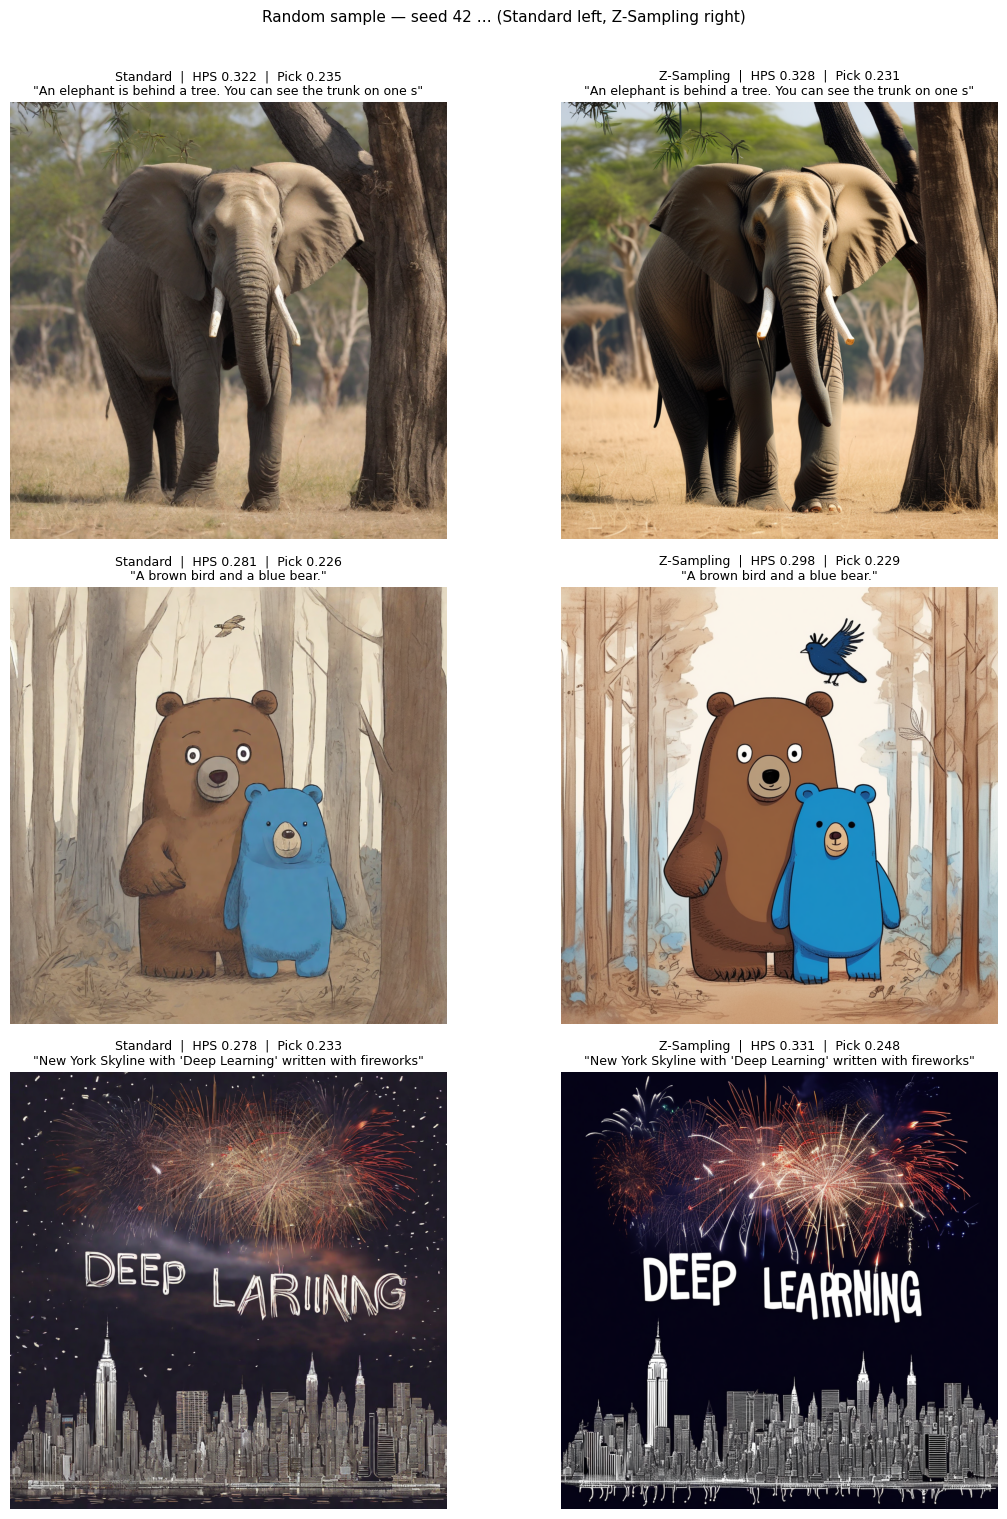

In [15]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

sample = df_results.sample(min(3, len(df_results)), random_state=random.randint(0, 9999))
sample = sample.merge(df_pairs[["prompt_idx", "seed", "standard_path", "zsampling_path"]],
                      on=["prompt_idx", "seed"])

n = len(sample)
fig, axes = plt.subplots(n, 2, figsize=(12, 5 * n))
if n == 1:
    axes = [axes]

for ax_row, (_, row) in zip(axes, sample.iterrows()):
    for ax, path_col, hps_col, pick_col, label in [
        (ax_row[0], "standard_path",  "hps_standard",  "pick_standard",  "Standard"),
        (ax_row[1], "zsampling_path", "hps_zsampling", "pick_zsampling", "Z-Sampling"),
    ]:
        ax.imshow(mpimg.imread(row[path_col]))
        ax.axis("off")
        ax.set_title(
            f"{label}  |  HPS {row[hps_col]:.3f}  |  Pick {row[pick_col]:.3f}\n"
            f"\"{row['prompt'][:60]}\"",
            fontsize=9)

fig.suptitle(f"Random sample — seed {int(sample.iloc[0]['seed'])} … (Standard left, Z-Sampling right)",
             fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

In [16]:
metrics = ["hps", "aes", "pick", "ir"]
metric_names = {"hps": "HPS v2", "aes": "AES", "pick": "PickScore", "ir": "IR"}

summary_rows = []
for m in metrics:
    std_mean = df_results[f"{m}_standard"].mean()
    zs_mean = df_results[f"{m}_zsampling"].mean()
    delta = zs_mean - std_mean
    wins_zs = (df_results[f"{m}_zsampling"] > df_results[f"{m}_standard"]).sum()
    wins_std = (df_results[f"{m}_standard"] > df_results[f"{m}_zsampling"]).sum()
    summary_rows.append({
        "Metric": metric_names[m],
        "Standard (mean)": f"{std_mean:.2f}",
        "Z-Sampling (mean)": f"{zs_mean:.2f}",
        "Δ (Z - Std)": f"{delta:+.2f}",
        "Z wins": wins_zs,
        "Std wins": wins_std,
    })

df_summary = pd.DataFrame(summary_rows)
print("\n=== SDXL × DrawBench: Standard vs Z-Sampling ===")
print(f"(Mean over {len(df_results)} pairs: {NUM_PROMPTS} prompts × {len(SEEDS)} seeds)\n")
display(df_summary)


=== SDXL × DrawBench: Standard vs Z-Sampling ===
(Mean over 600 pairs: 200 prompts × 3 seeds)



,Metric,Standard (mean),Z-Sampling (mean),Δ (Z - Std),Z wins,Std wins
0,HPS v2,0.26,0.29,+0.02,540,60
1,AES,5.47,5.63,+0.15,420,180
2,PickScore,0.23,0.23,+0.00,351,249
3,IR,nan,nan,+nan,0,0


In [17]:
# Paper reference values (Table 1: SDXL, DrawBench)
paper_values = {
    "HPS v2": {"Standard": 28.81, "Z-Sampling": 30.50},
    "AES":    {"Standard": 5.56,  "Z-Sampling": 5.68},
    "PickScore": {"Standard": 22.31, "Z-Sampling": 22.46},
    "IR":     {"Standard": 60.75, "Z-Sampling": 79.97},
}

# HPS v2 is stored as a raw [0,1] score but the paper reports it x100 (a
# percentage). Scale it for display only so it is comparable to the paper.
display_scale = {"hps": 100.0, "aes": 1.0, "pick": 1.0, "ir": 1.0}

comparison_rows = []
for m, m_name in metric_names.items():
    s = display_scale[m]
    std_ours = df_results[f"{m}_standard"].mean() * s
    zs_ours = df_results[f"{m}_zsampling"].mean() * s
    std_paper = paper_values[m_name]["Standard"]
    zs_paper = paper_values[m_name]["Z-Sampling"]
    comparison_rows.append({
        "Metric": m_name,
        "Std (paper)": std_paper,
        "Std (ours)": f"{std_ours:.2f}",
        "Z-Samp (paper)": zs_paper,
        "Z-Samp (ours)": f"{zs_ours:.2f}",
    })

df_comparison = pd.DataFrame(comparison_rows)
print("\n=== Reproduction vs Paper (Table 1: SDXL, DrawBench) ===")
display(df_comparison)


=== Reproduction vs Paper (Table 1: SDXL, DrawBench) ===


,Metric,Std (paper),Std (ours),Z-Samp (paper),Z-Samp (ours)
0,HPS v2,28.81,26.44,30.50,28.63
1,AES,5.56,5.47,5.68,5.63
2,PickScore,22.31,0.23,22.46,0.23
3,IR,60.75,nan,79.97,nan


In [18]:
# Per-seed breakdown
print("\n=== Per-seed results ===")
for seed in SEEDS:
    subset = df_results[df_results["seed"] == seed]
    print(f"\nSeed {seed} ({len(subset)} pairs):")
    for m in metrics:
        std = subset[f"{m}_standard"].mean()
        zs = subset[f"{m}_zsampling"].mean()
        print(f"  {metric_names[m]:>10}: Standard={std:.2f}  Z-Sampling={zs:.2f}  Δ={zs-std:+.2f}")


=== Per-seed results ===

Seed 42 (200 pairs):
      HPS v2: Standard=0.26  Z-Sampling=0.28  Δ=+0.02
         AES: Standard=5.48  Z-Sampling=5.60  Δ=+0.12
   PickScore: Standard=0.23  Z-Sampling=0.23  Δ=+0.00
          IR: Standard=nan  Z-Sampling=nan  Δ=+nan

Seed 123 (200 pairs):
      HPS v2: Standard=0.27  Z-Sampling=0.29  Δ=+0.02
         AES: Standard=5.50  Z-Sampling=5.64  Δ=+0.15
   PickScore: Standard=0.23  Z-Sampling=0.23  Δ=+0.00
          IR: Standard=nan  Z-Sampling=nan  Δ=+nan

Seed 2026 (200 pairs):
      HPS v2: Standard=0.27  Z-Sampling=0.29  Δ=+0.02
         AES: Standard=5.45  Z-Sampling=5.63  Δ=+0.18
   PickScore: Standard=0.23  Z-Sampling=0.23  Δ=+0.00
          IR: Standard=nan  Z-Sampling=nan  Δ=+nan


## 6. Save Final Results

In [19]:
df_results.to_csv(DRIVE_DIR / "sdxl_drawbench_eval_results.csv", index=False)
df_summary.to_csv(DRIVE_DIR / "sdxl_drawbench_eval_summary.csv", index=False)
df_comparison.to_csv(DRIVE_DIR / "sdxl_drawbench_eval_comparison.csv", index=False)
print("Results saved to Drive.")

Results saved to Drive.
